In [1]:
import tensorflow as tf
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

import os
import sys
from pathlib import Path

# Works on the Vast.ai VM and on your PC (run the notebook from the notebooks/ folder)
REPO = next(
    (p for p in (Path("/workspace/NeuroVision"), Path.cwd().parent) if (p / "src" / "neurovision").exists()),
    None,
)
if REPO is None:
    raise RuntimeError("NeuroVision repo not found: edit REPO in this cell.")
sys.path.append(str(REPO / "src"))
os.chdir(REPO / "notebooks")
(REPO / "reports").mkdir(exist_ok=True)

2026-10-29 11:20:45.185041: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793272845.210472    9208 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793272845.218443    9208 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793272845.238406    9208 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793272845.238430    9208 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793272845.238433    9208 computation_placer.cc:177] computation placer alr

# Part 2 - 01 Data preparation for MobileNetV2

Same dataset, same loader and same split as Part 1, so both models are compared on the same test set.

## Imports and configuration

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from neurovision.data import CLASSES, split_fingerprint
from neurovision.preprocessing import prepare_data, make_dataset, encoder
from neurovision.transfer import IMAGE_SIZE, build_augmentation, build_mobilenet_preprocessing

RAW_DIR = "../data/raw"

## Load, clean and split (same function and seed as Part 1)

In [3]:
data = prepare_data(RAW_DIR, size=IMAGE_SIZE, seed=42)
X_train, y_train, p_train = data["train"]
X_val, y_val, p_val = data["val"]
X_test, y_test, p_test = data["test"]

print(X_train.shape, X_val.shape, X_test.shape)
print(X_train.dtype, X_train.min(), X_train.max())

(4708, 224, 224, 3) (1009, 224, 224, 3) (1009, 224, 224, 3)
uint8 0 255


## Split fingerprints (identical values in Part 1 and Part 2 prove the same split)

In [4]:
for name, paths in [("train", p_train), ("val", p_val), ("test", p_test)]:
    print(name, split_fingerprint(paths, RAW_DIR))

train 9e31d0de7223
val 12f1beda118e
test 36c6aa5c7ee7


## Leakage check and class proportions per split

In [5]:
print(len(set(p_train) & set(p_val)), len(set(p_train) & set(p_test)), len(set(p_val) & set(p_test)))

for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    values, counts = np.unique(labels, return_counts=True)
    print(name, dict(zip(values, np.round(counts / len(labels), 3))))

0 0 0
train {np.str_('glioma'): np.float64(0.241), np.str_('meningioma'): np.float64(0.243), np.str_('notumor'): np.float64(0.257), np.str_('pituitary'): np.float64(0.259)}
val {np.str_('glioma'): np.float64(0.241), np.str_('meningioma'): np.float64(0.243), np.str_('notumor'): np.float64(0.258), np.str_('pituitary'): np.float64(0.259)}
test {np.str_('glioma'): np.float64(0.241), np.str_('meningioma'): np.float64(0.244), np.str_('notumor'): np.float64(0.257), np.str_('pituitary'): np.float64(0.259)}


## Class weights computed on the training set only

In [6]:
y_train_idx = encoder.transform(y_train)
weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train_idx)
class_weight = dict(enumerate(weights))
print(class_weight)

{0: np.float64(1.0379188712522045), 1: np.float64(1.0288461538461537), 2: np.float64(0.9711221122112211), 3: np.float64(0.9663382594417077)}


## MobileNetV2 preprocessing: pixels from [0, 255] to [-1, 1]

I0000 00:00:1793272875.922507    9208 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 96 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:08:00.0, compute capability: 8.6


Before: 0.0 255.0
After: -1.0 1.0
Max difference with preprocess_input: 1.1920929e-07


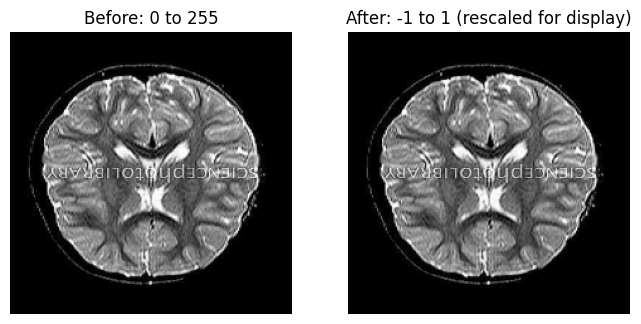

In [7]:
batch = X_train[:8].astype("float32")
expected = preprocess_input(batch.copy())
actual = build_mobilenet_preprocessing()(batch).numpy()

print("Before:", batch.min(), batch.max())
print("After:", actual.min(), actual.max())
print("Max difference with preprocess_input:", np.abs(expected - actual).max())

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(X_train[0])
axes[0].set_title("Before: 0 to 255")
axes[0].axis("off")
axes[1].imshow((actual[0] + 1) / 2)
axes[1].set_title("After: -1 to 1 (rescaled for display)")
axes[1].axis("off")
plt.savefig("../reports/part2_preprocessing.png", dpi=150, bbox_inches="tight")
plt.show()

## Augmentation preview (applied to the training set only, inside the model)

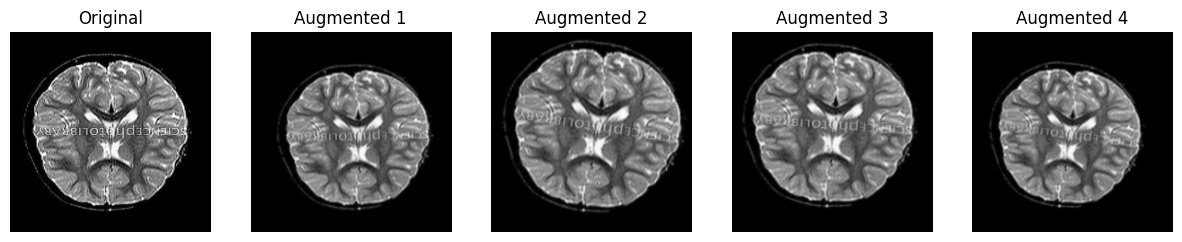

In [8]:
augmentation = build_augmentation()
sample = X_train[:1].astype("float32")

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(X_train[0])
axes[0].set_title("Original")
axes[0].axis("off")
for i in range(1, 5):
    augmented = augmentation(sample, training=True)[0].numpy().clip(0, 255).astype("uint8")
    axes[i].imshow(augmented)
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")
plt.savefig("../reports/part2_augmentation.png", dpi=150, bbox_inches="tight")
plt.show()

## Build the tf.data datasets (labels one-hot encoded)

In [9]:
train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

xb, yb = next(iter(train_ds))
print(xb.shape, xb.dtype, yb.shape)

(32, 224, 224, 3) <dtype: 'uint8'> (32, 4)
